In [1]:
#Laboratorios 16: Algoritmo KNN

In [1]:
# 1. Importamos librerias
import pandas as pd
import matplotlib.pyplot as plt
# Librerias de Machine Learning
from sklearn.datasets import load_wine#Importamos el dataset de vinos
from sklearn.model_selection import train_test_split# Importamos el metodo de dividir
from sklearn.preprocessing import StandardScaler#Importamos el metodo para escalar
from sklearn.neighbors import KNeighborsClassifier# Importamos el algoritmo
from sklearn.metrics import ( accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)# Importamos las metricas
import seaborn as sns

In [2]:
# 2. Cargamos el dataset
vino = load_wine(as_frame= True)
print (vino.DESCR)

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

In [3]:
# Creamos el dataframe
dfVino = vino.frame
dfVino.head(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0


In [4]:
vino.target_names

array(['class_0', 'class_1', 'class_2'], dtype='<U7')

In [5]:
# Cambiamos la columna Target por Clases
dfVino.rename(columns={"target":"clase"}, inplace=True)

In [6]:
dfVino["clase"] = dfVino["clase"].map(
    {
        0:"Clase 0",
        1:"Clase 1",
        2:"Clase 2"
    }
)

In [7]:
dfVino.sample(5)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,clase
97,12.29,1.41,1.98,16.0,85.0,2.55,2.50,0.29,1.77,2.90,1.23,2.74,428.0,Clase 1
69,12.21,1.19,1.75,16.8,151.0,1.85,1.28,0.14,2.50,2.85,1.28,3.07,718.0,Clase 1
77,11.84,2.89,2.23,18.0,112.0,1.72,1.32,0.43,0.95,2.65,0.96,2.52,500.0,Clase 1
45,14.21,4.04,2.44,18.9,111.0,2.85,2.65,0.30,1.25,5.24,0.87,3.33,1080.0,Clase 0
40,13.56,1.71,2.31,16.2,117.0,3.15,3.29,0.34,2.34,6.13,0.95,3.38,795.0,Clase 0


In [8]:
dfVino.head(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,Clase 0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,Clase 0


In [9]:
# Variables predictoras
X = dfVino.drop(columns=["clase"])

In [10]:
#Variable Objetivo
y= dfVino["clase"]

In [11]:
print ("Variables predictoras")
print(X.columns)
print("--------------------")
print("Variable objetivo")
print(y.name)

Variables predictoras
Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline'],
      dtype='str')
--------------------
Variable objetivo
clase


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, #Variables predictorsas
    y, #Variable Objetivo
    test_size=0.30, #Porcentaje para pruebas
    random_state=42, # Semilla paar garantizar la reproducibilidad
    stratify=y # Para que esten equilibradas las clases
)

In [13]:
print ("X_train: ", X_train.shape)
print ("X_test: ", X_test.shape)
print ("--------------------------")
print ("y_train: ", y_train.shape)
print ("y_test: ", y_test.shape)

X_train:  (124, 13)
X_test:  (54, 13)
--------------------------
y_train:  (124,)
y_test:  (54,)


In [14]:
## 6. Escalado de Variables
scaler = StandardScaler()

In [15]:
# Escalamos las variables numericas, es decir todas las predictoras
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
print("Datos escalados")
print(X_train_scaled)

Datos escalados
[[ 0.98268636 -0.52764049  0.17359827 ...  0.85746167  0.43782507
   1.86317967]
 [ 0.95793708 -0.74551086  1.25550363 ...  1.03209459  0.15956344
   1.74910798]
 [ 0.40107814 -0.61289411  1.77780276 ...  0.59551231  0.26208088
   0.42913559]
 ...
 [ 0.19070921 -0.36660586  1.44203903 ... -1.50008262 -1.86149473
  -1.05379636]
 [-0.87351008  2.30467436  0.65859033 ... -0.88886743 -1.94936683
  -0.09233499]
 [-0.390899   -0.87812761 -1.28137789 ...  0.1152718  -1.48071566
  -0.97231658]]


In [17]:
# 7. Entrenamiento de los datos
modelo = KNeighborsClassifier(
    n_neighbors=3 # Numero de vecinos a checar
)

In [18]:
#Entrenamos el modelo
modelo.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Clase 0','Clase 1','Clase 2']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [19]:
# Predicicón de pruebas
prediccion = modelo.predict(X_test_scaled)

In [20]:
pd.DataFrame(
    {
        "Clase real: " : y_test.values,
        "Clase predicción: " : prediccion
    }
).head(30)

,Clase real:,Clase predicción:
0,Clase 0,Clase 0
1,Clase 1,Clase 1
2,Clase 0,Clase 0
3,Clase 0,Clase 0
4,Clase 0,Clase 0
5,Clase 0,Clase 0
6,Clase 2,Clase 2
7,Clase 1,Clase 1
8,Clase 1,Clase 0
9,Clase 2,Clase 2


In [21]:
accuracy= accuracy_score(y_test, prediccion)
print (f"Accuracy / Exactitud del modelo KNN: {accuracy : .4f}")

Accuracy / Exactitud del modelo KNN:  0.9444


In [22]:
matrizConfusion = confusion_matrix(y_test, prediccion)
matrizConfusionDF = pd.DataFrame(
    matrizConfusion, 
    index = modelo.classes_,
    columns = modelo.classes_
)
matrizConfusionDF

,Clase 0,Clase 1,Clase 2
Clase 0,18,0,0
Clase 1,1,18,2
Clase 2,0,0,15


In [23]:
print(classification_report(y_test, prediccion))

              precision    recall  f1-score   support

     Clase 0       0.95      1.00      0.97        18
     Clase 1       1.00      0.86      0.92        21
     Clase 2       0.88      1.00      0.94        15

    accuracy                           0.94        54
   macro avg       0.94      0.95      0.94        54
weighted avg       0.95      0.94      0.94        54



In [24]:
# Variables importantes
corr = dfVino.corr(numeric_only= True)

<Axes: >

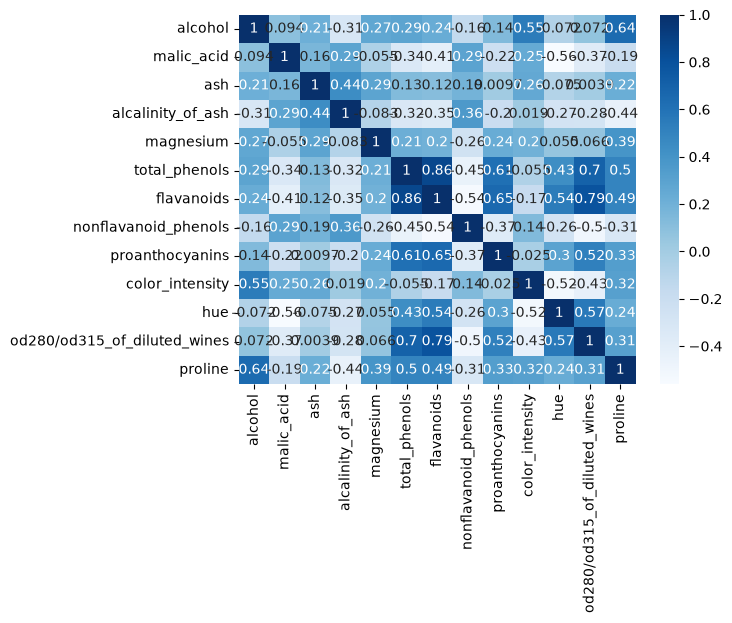

In [25]:
sns.heatmap(corr, annot= True, cmap="Blues")